# Diabetes Detection System

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import ( confusion_matrix, classification_report, roc_curve, roc_auc_score, precision_score, recall_score, f1_score, accuracy_score)
import matplotlib.pyplot as plt

In [ ]:
path = "/content/2025-09-01T04-03-42.625Z-2025-07-04T13-24-57.561Z-diabetes.csv"
df = pd.read_csv(path)
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [ ]:
df.shape

(768, 9)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [ ]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [ ]:
df.isna().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [ ]:
cols_with_zero_missing = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
df[cols_with_zero_missing] = df[cols_with_zero_missing].replace(0, np.nan)

In [ ]:
df.isna().sum()

,0
Pregnancies,0
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [ ]:
df[cols_with_zero_missing] = df[cols_with_zero_missing].fillna(df[cols_with_zero_missing].median())

In [ ]:
df.isna().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


###Train Test Split

In [ ]:
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

In [ ]:
X.shape

(768, 8)

In [ ]:
y.shape

(768,)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

In [ ]:
print("\nTrain shape:", X_train.shape, "Test shape:", X_test.shape)


Train shape: (614, 8) Test shape: (154, 8)


# Train

In [ ]:
pipelines = {
    "LogisticRegression": Pipeline([("scaler", StandardScaler()), ("clf", LogisticRegression(max_iter=1000, random_state=42))]),
    "KNN": Pipeline([("scaler", StandardScaler()), ("clf", KNeighborsClassifier())]),
    "DecisionTree": Pipeline([("clf", DecisionTreeClassifier(random_state=42))]),
    "RandomForest": Pipeline([("clf", RandomForestClassifier(n_estimators=200, random_state=42))])
}


In [ ]:
results = []
model_objects = {}

for name, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    model_objects[name] = pipe
    y_pred = pipe.predict(X_test)
    # For ROC we need predicted probabilities; handle classifiers without predict_proba gracefully
    try:
        y_proba = pipe.predict_proba(X_test)[:,1]
    except Exception:
        # Fallback: use decision_function then min-max to convert (not necessary here)
        y_proba = None

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    auc = roc_auc_score(y_test, y_proba) if y_proba is not None else np.nan

    results.append({
        "model": name,
        "accuracy": acc,
        "precision": prec,
        "recall": rec,
        "f1": f1,
        "auc": auc
    })
    print(f"\n=== {name} ===")
    print("Classification report:\n", classification_report(y_test, y_pred, zero_division=0))
    cm = confusion_matrix(y_test, y_pred)
    print("Confusion matrix:\n", cm)


=== LogisticRegression ===
Classification report:
               precision    recall  f1-score   support

           0       0.75      0.82      0.78       100
           1       0.60      0.50      0.55        54

    accuracy                           0.71       154
   macro avg       0.68      0.66      0.67       154
weighted avg       0.70      0.71      0.70       154

Confusion matrix:
 [[82 18]
 [27 27]]

=== KNN ===
Classification report:
               precision    recall  f1-score   support

           0       0.80      0.83      0.81       100
           1       0.66      0.61      0.63        54

    accuracy                           0.75       154
   macro avg       0.73      0.72      0.72       154
weighted avg       0.75      0.75      0.75       154

Confusion matrix:
 [[83 17]
 [21 33]]

=== DecisionTree ===
Classification report:
               precision    recall  f1-score   support

           0       0.74      0.79      0.76       100
           1       0.55   

## Output

In [ ]:
results_df = pd.DataFrame(results).set_index("model").round(4)
results_df

,accuracy,precision,recall,f1,auc
model,,,,,
LogisticRegression,0.7078,0.6000,0.5000,0.5455,0.8130
KNN,0.7532,0.6600,0.6111,0.6346,0.7886
DecisionTree,0.6818,0.5532,0.4815,0.5149,0.6357
RandomForest,0.7403,0.6522,0.5556,0.6000,0.8161


/tmp/ipython-input-2281213060.py:17: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


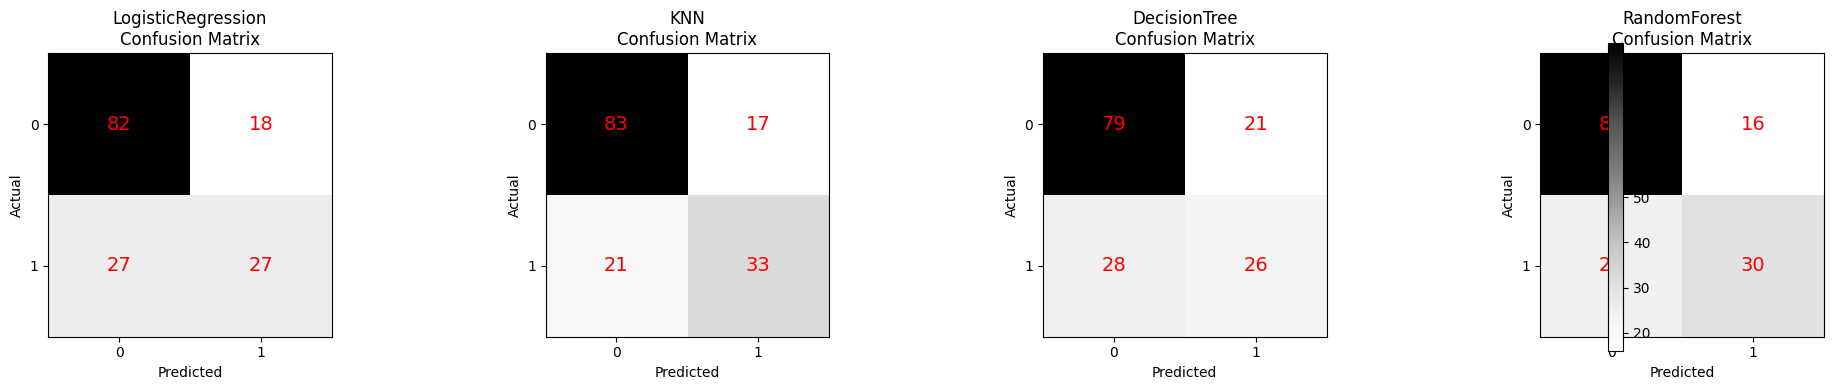

In [ ]:
# Plot confusion matrices for each model side-by-side
fig, axes = plt.subplots(1, len(pipelines), figsize=(5*len(pipelines), 4))
if len(pipelines) == 1:
    axes = [axes]

for ax, (name, pipe) in zip(axes, pipelines.items()):
    y_pred = model_objects[name].predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    im = ax.imshow(cm, interpolation='nearest', cmap=plt.cm.Greys)
    ax.set_title(f"{name}\nConfusion Matrix")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_xticks([0,1]); ax.set_yticks([0,1])
    for (i, j), val in np.ndenumerate(cm):
        ax.text(j, i, str(val), ha="center", va="center", color="red", fontsize=14)
fig.colorbar(im, ax=axes, fraction=0.02)
plt.tight_layout()
plt.show()

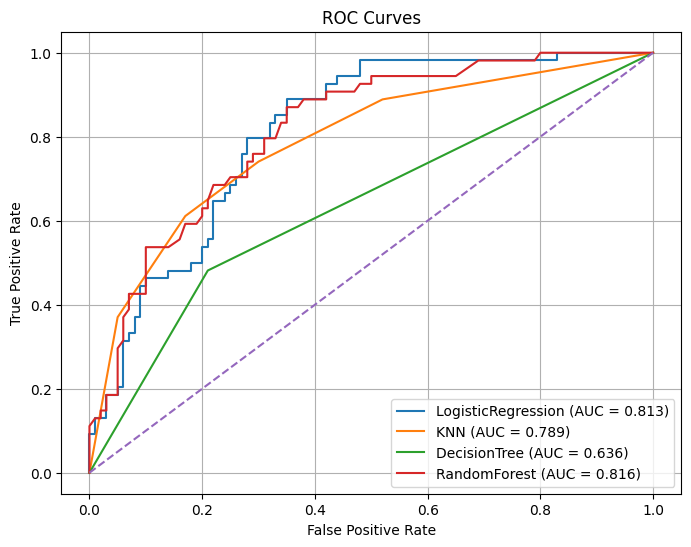

In [ ]:
# Plot ROC curves
plt.figure(figsize=(8,6))
for name, pipe in pipelines.items():
    try:
        y_proba = model_objects[name].predict_proba(X_test)[:,1]
        fpr, tpr, _ = roc_curve(y_test, y_proba)
        auc_score = roc_auc_score(y_test, y_proba)
        plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_score:.3f})")
    except Exception:
        # skip if predict_proba not available
        pass

plt.plot([0,1], [0,1], linestyle='--')  # random baseline
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves")
plt.legend()
plt.grid(True)
plt.show()